# Tutorial 03 - Project 1: Modular Sales Inventory Processing
This notebook processes raw inventory lines, instantiates object-oriented `Product` entities, and plots total inventory valuation.


In [1]:
import sys
sys.path.append("..")
from utils import clean_lines, clean_lines_loop, parse_products, Product
import matplotlib.pyplot as plt

# 1. Read raw text data
with open("../data/raw/data.txt", "r", encoding="utf-8") as f:
    raw_lines = f.readlines()

print(f"Total Raw Lines: {len(raw_lines)}")


Total Raw Lines: 8


### 2. Compare Loop vs. List Comprehension Cleaning


In [2]:
cleaned_loop = clean_lines_loop(raw_lines)
cleaned_comp = clean_lines(raw_lines)

assert cleaned_loop == cleaned_comp
print(f"Cleaned Lines ({len(cleaned_comp)} records):")
for line in cleaned_comp:
    print(f"  {line}")


Cleaned Lines (6 records):
  Laptop,1000,3
  Phone,500,5
  "Corrupted Row",InvalidPrice,10
  Tablet,700,2
  Monitor,300,4
  Camera,400,1


### 3. Parse Records and Instantiate Product Objects


In [3]:
parsed_tuples = parse_products(cleaned_comp)
products = [Product(name, price, qty) for name, price, qty in parsed_tuples]

for p in products:
    print(f"{p} -> Inventory Value: ${p.total_value():,.2f}")


[Warning] Parsing error in '"Corrupted Row",InvalidPrice,10': could not convert string to float: 'InvalidPrice'
Product(Laptop, Price=1000.00, Qty=3) -> Inventory Value: $3,000.00
Product(Phone, Price=500.00, Qty=5) -> Inventory Value: $2,500.00
Product(Tablet, Price=700.00, Qty=2) -> Inventory Value: $1,400.00
Product(Monitor, Price=300.00, Qty=4) -> Inventory Value: $1,200.00
Product(Camera, Price=400.00, Qty=1) -> Inventory Value: $400.00


### 4. Valuation Bar Chart


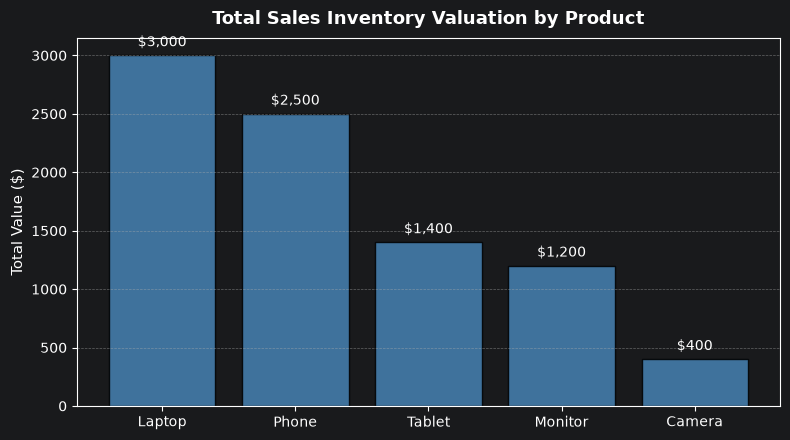

In [4]:
names = [p.name for p in products]
values = [p.total_value() for p in products]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(names, values, color="steelblue", edgecolor="black", alpha=0.85)

ax.set_title("Total Sales Inventory Valuation by Product", fontsize=13, fontweight='bold', pad=10)
ax.set_ylabel("Total Value ($)", fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 50, f"${y:,.0f}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()
